# Ex 1 - Generate Time Series Forecasts with your buisness data using SAP RPT-TS

In [2]:
import sys
print(sys.base_prefix)
print(sys.prefix)

import hana_ml
print(hana_ml.__version__)

import pandas as pd
pd.set_option('max_colwidth', None) 

C:\Users\D059078\AppData\Local\Programs\Python\Python312
C:\Users\D059078\AppData\Local\Programs\Python\envs\hanaml_env
2.30.26091504


In [3]:
import hana_ml.dataframe as dataframe
#conn = dataframe.ConnectionContext(userkey='MYHANACLOUD')
conn = dataframe.ConnectionContext(userkey='HC24Q1_VECENG')
#conn = dataframe.ConnectionContext(userkey='HCvalML_D98')
print('Connection successful!', conn.connection.isconnected())
print(conn.hana_version())

Connection successful! True
4.00.000.00.1789465914 (fa/CE2026.28)


# Data - Bike Sharing data

<br>
[data set reference UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)  [DOI 10.24432/C5W894](10.24432/C5W894) by Hadi Fanaee-T <br>
Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.<br>

This dataset contains the hourly and daily count of rental bikes between years 2011 and 2012 in Capital bikeshare system with the corresponding weather and seasonal information.
- characteristics multivariate
- task regression/time series
- Forecast history 17389 rows

<br>
Rossmann small store sales data, 102 stores, 48-day horizon, promo, holiday and open-day covariates pre-configured <br>
Columns <br>
- Date, Store, Sales <br>
- Future known co-vars: Open, Promo, StateHoliday, SchoolhHoliday <br>
- Past only co-vars: Customers <br>
- train_ext.csv 96084 rows, 102 stores <br>
- test_ext.csv 4896 rows <br>
- Forecast horizon: 48 days

### Data exploration

https://github.com/SAP-samples/mee-samples/blob/main/Hands-on Tutorial Machine Learning with SAP HANA Cloud and BAS/HOTELNIGHTS.csv

In [4]:
import pandas as pd
df_data = pd.read_csv("./RossmannSmall/train_ext.csv", sep=",")
df_data.Date = pd.to_datetime(df_data.Date, format='%Y-%m-%d') 
display(df_data.head(2))
display(df_data.dtypes)

import hana_ml.dataframe as dataframe
upload_hdf = dataframe.create_dataframe_from_pandas(connection_context=conn, 
                                                   pandas_df=df_data, 
                                                   table_name='#RossmannSmall_Train',
                                                   force=True,
                                                   replace=False)
upload_hdf.dtypes()

,Store,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,2015-07-31,5263,555,1,1,NaN,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,1,2015-07-30,5020,546,1,1,NaN,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


Store                                 int64
Date                         datetime64[ns]
Sales                                 int64
Customers                             int64
Open                                  int64
Promo                                 int64
StateHoliday                         object
SchoolHoliday                         int64
StoreType                            object
Assortment                           object
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                        object
dtype: object

100%|████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:08<00:00,  4.10s/it]


[('Store', 'INT', 10, 10, 10, 0),
 ('Date', 'TIMESTAMP', 27, 27, 27, 0),
 ('Sales', 'INT', 10, 10, 10, 0),
 ('Customers', 'INT', 10, 10, 10, 0),
 ('Open', 'INT', 10, 10, 10, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0)]

In [5]:
import pandas as pd
df_data = pd.read_csv("./RossmannSmall/test_ext.csv", sep=",")
df_data.Date = pd.to_datetime(df_data.Date, format='%Y-%m-%d') 
display(df_data.head(2))
display(df_data.dtypes)

import hana_ml.dataframe as dataframe
upload_hdf = dataframe.create_dataframe_from_pandas(connection_context=conn, 
                                                   pandas_df=df_data, 
                                                   table_name='#RossmannSmall_Test',
                                                   force=True,
                                                   replace=False)
upload_hdf.dtypes()


,Store,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,2015-09-17,1.0,1,NaN,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,1,2015-09-16,1.0,1,NaN,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN


Store                                 int64
Date                         datetime64[ns]
Open                                float64
Promo                                 int64
StateHoliday                         object
SchoolHoliday                         int64
StoreType                            object
Assortment                           object
CompetitionDistance                 float64
CompetitionOpenSinceMonth           float64
CompetitionOpenSinceYear            float64
Promo2                                int64
Promo2SinceWeek                     float64
Promo2SinceYear                     float64
PromoInterval                        object
dtype: object

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.81it/s]


[('Store', 'INT', 10, 10, 10, 0),
 ('Date', 'TIMESTAMP', 27, 27, 27, 0),
 ('Open', 'DOUBLE', 15, 15, 15, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0)]

Point to the table that contains the data

In [6]:
data_hdf = conn.table('#RossmannSmall_Train')
tdata_hdf = conn.table('#RossmannSmall_Test')
#data_hdf = data_hdf.filter(""" COUNTRYOFRESIDENCE in ('Germany', 'France', 'United States') """)

Retrieve a few rows of data

In [7]:
data_hdf.head(1).collect()

,Store,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,16,2015-07-18,5288,550,1,0,None,0,a,c,3270.0,None,None,0,None,None,None


Get some statistics of the columns' content

In [8]:
data_hdf.describe().collect()

,column,count,unique,nulls,mean,std,min,max,min_value,max_value,median,25_percent_cont,25_percent_disc,50_percent_cont,50_percent_disc,75_percent_cont,75_percent_disc
0,Store,91852,102,0,75.477072,87.286173,1.0,909.0,1,909,68.0,35.0,35.0,68.0,68.0,101.00,101.0
1,Sales,91852,11873,0,5554.915484,3449.993497,0.0,41551.0,0,41551,5702.0,3806.0,3806.0,5702.0,5702.0,7599.25,7599.0
2,Customers,91852,1744,0,579.567435,357.198586,0.0,2849.0,0,2849,589.0,419.0,419.0,589.0,589.0,779.00,779.0
3,Open,91852,2,0,0.828616,0.376846,0.0,1.0,0,1,1.0,1.0,1.0,1.0,1.0,1.00,1.0
4,Promo,91852,2,0,0.381244,0.485694,0.0,1.0,0,1,0.0,0.0,0.0,0.0,0.0,1.00,1.0
5,SchoolHoliday,91852,2,0,0.176817,0.381515,0.0,1.0,0,1,0.0,0.0,0.0,0.0,0.0,0.00,0.0
6,CompetitionDistance,91852,97,0,6157.545617,9395.199487,40.0,58260.0,40,58260,2380.0,1070.0,1070.0,2380.0,2380.0,7340.00,7340.0
7,CompetitionOpenSinceMonth,60354,12,31498,7.162541,3.362066,1.0,12.0,1,12,8.0,4.0,4.0,8.0,8.0,10.00,10.0
8,CompetitionOpenSinceYear,60354,15,31498,2008.579083,4.224428,1999.0,2015.0,1999,2015,2009.0,2006.0,2006.0,2009.0,2009.0,2013.00,2013.0
9,Promo2,91852,2,0,0.567021,0.495490,0.0,1.0,0,1,1.0,0.0,0.0,1.0,1.0,1.00,1.0


### Explore the tine series data
Aggregate the hotel nights by month

In [9]:
data_hdf.distinct('Store').sort('Store').head(5).collect()

,Store
0,1
1,3
2,7
3,8
4,9


In [10]:
agg_hdf = data_hdf.agg([('sum', 'Sales', 'Sales_SUM')], group_by=['Store'])
#agg_hdf = agg_hdf.to_head('COUNTRYOFRESIDENCE')
agg_hdf = agg_hdf.sort(['Sales_SUM'], desc=True)
display(agg_hdf.tail(3).collect())
display(agg_hdf.head(3).collect())
#display(agg_hdf.select_statement)

,Store,Sales_SUM
0,22,2801506
1,72,2753676
2,32,2526117


,Store,Sales_SUM
0,84,10092722
1,25,8376557
2,64,8070070


Plot the daily sales data

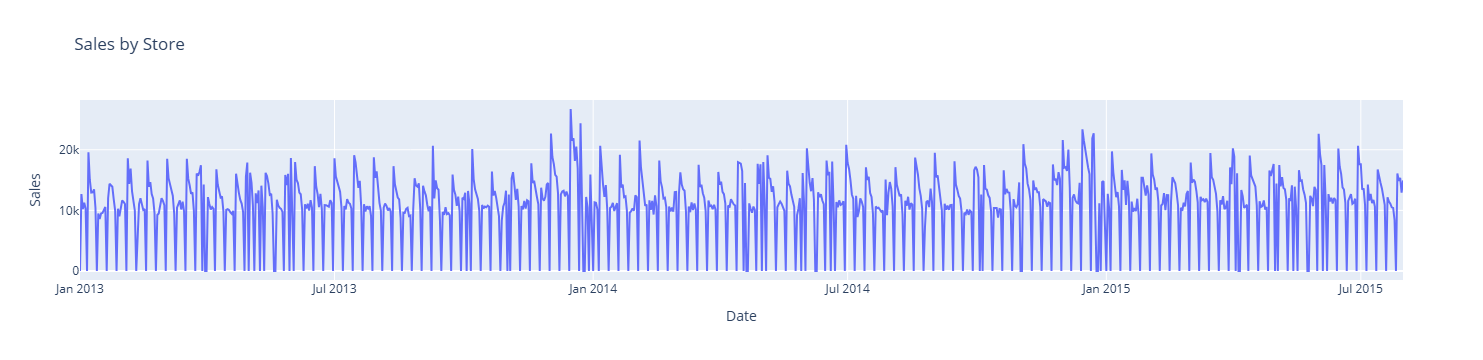

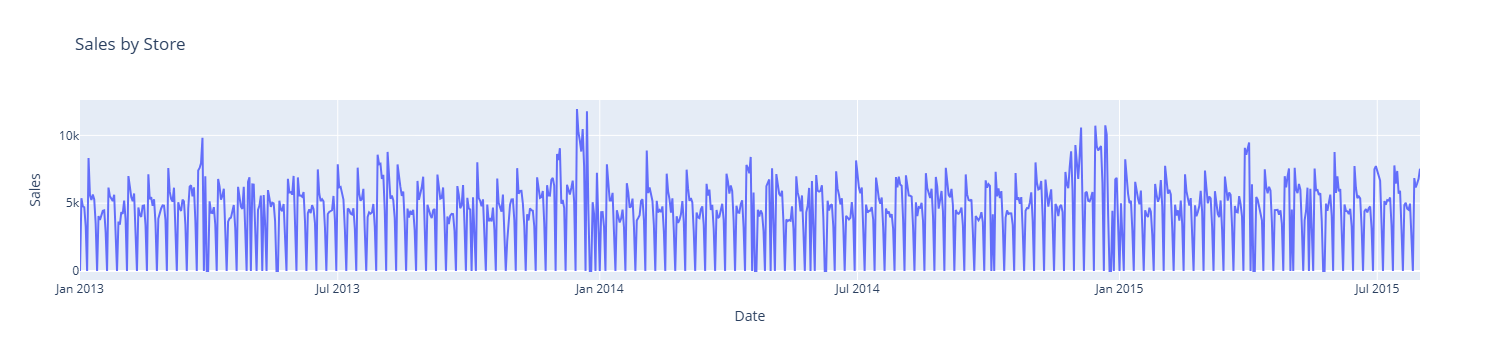

In [11]:
hdf_data_plot = data_hdf.select('Sales', 'Date', 'Store').sort('Date') #,\'64\',\'25\'
import plotly.express as px
fig = px.line(hdf_data_plot.filter('"Store" in (\'84\')').collect() , x='Date', y='Sales', title='Sales by Store')
fig.show()
fig = px.line(hdf_data_plot.filter('"Store" in (\'53\')').collect() , x='Date', y='Sales', title='Sales by Store')
fig.show()

In [12]:
#display(data_hdf.dtypes())
# DATE / SECONDDATE instead of LONGDATE 
data_hdf=data_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
tdata_hdf=tdata_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
display(data_hdf.dtypes())

[('Store', 'INT', 10, 10, 10, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0),
 ('Customers', 'INT', 10, 10, 10, 0),
 ('Open', 'INT', 10, 10, 10, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0)]

# RPT-ts Pipeline Predict

## Predict with Horizon_Length

In [62]:
# No fit(); no explicit skip_fit; nothing to fall back to.
        # {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": [0], "POINT_FORECAST": ["median"], "CLIP_MIN": [0], "CLIP_MAX": [999999]}}
# CONFIDENCE_LEVEL must be one of the specified values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.98]
# , "FORECAST_LENGTH": [10]
# TSFM::predict: no future rows found. Append rows with TARGET=NULL to define the horizon, or pass FORECAST_LENGTH=N

In [13]:
import pandas as pd
pd.set_option('max_colwidth', None) 

In [14]:
from hana_ml.algorithms.pal.pipeline import Pipeline
#pipe = Pipeline(pipeline={"TSFM": {"args": {}, "inputs": {"data": "ROWDATA"}}})
pipe = Pipeline(pipeline={"TSFM": {"args": {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 999999, 
                                            "FORECAST_LENGTH": 48}, 
                                   "inputs": {"data": "ROWDATA"}}})

result = pipe.predict(data_hdf.filter('"Store" in (\'84\')').select('DATE', 'Sales'), key='DATE', 
                                             output_prediction_interval=True, confidence_level=0.9)#, endog="HOTELNIGHTS")

In [15]:
print(conn.last_execute_statement)

DO
BEGIN
DECLARE param_name VARCHAR(5000) ARRAY;
DECLARE int_value INTEGER ARRAY;
DECLARE double_value DOUBLE ARRAY;
DECLARE string_value VARCHAR(5000) ARRAY;
param_name[1] := N'OUTPUT_PREDICTION_INTERVAL';
int_value[1] := 1;
double_value[1] := NULL;
string_value[1] := NULL;
param_name[2] := N'CONFIDENCE_LEVEL';
int_value[2] := NULL;
double_value[2] := 0.9;
string_value[2] := NULL;
param_name[3] := N'PIPELINE';
int_value[3] := NULL;
double_value[3] := NULL;
string_value[3] := N'{"TSFM": {"args": {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 999999, "FORECAST_LENGTH": 48}, "inputs": {"data": "ROWDATA"}}}';
params = UNNEST(:param_name, :int_value, :double_value, :string_value);
in_0 = SELECT "DATE", "Sales" FROM (SELECT "DATE", "Sales" FROM (SELECT * FROM (SELECT "Store", "DATE", "Sales", "Customers", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "Comp

In [16]:

display(result.head(10).collect())

,ID,SCORES
0,2015-08-01,"{""value"":11289.3271484375,""lower"":8351.6689453125,""upper"":14887.7021484375}"
1,2015-08-02,"{""value"":155.2314453125,""lower"":-3047.89453125,""upper"":3495.15185546875}"
2,2015-08-03,"{""value"":14636.54296875,""lower"":10969.025390625,""upper"":18376.087890625}"
3,2015-08-04,"{""value"":13310.0205078125,""lower"":9874.3583984375,""upper"":16806.73046875}"
4,2015-08-05,"{""value"":12927.59765625,""lower"":9624.3583984375,""upper"":16269.607421875}"
5,2015-08-06,"{""value"":10699.3349609375,""lower"":7645.3173828125,""upper"":14013.7177734375}"
6,2015-08-07,"{""value"":12040.8515625,""lower"":8987.16796875,""upper"":15589.14453125}"
7,2015-08-08,"{""value"":10382.091796875,""lower"":7286.6064453125,""upper"":13664.380859375}"
8,2015-08-09,"{""value"":0.0,""lower"":-3333.2275390625,""upper"":3218.43359375}"
9,2015-08-10,"{""value"":14915.8857421875,""lower"":11586.57421875,""upper"":18695.546875}"


In [17]:
predres_hdf=result.sort("ID").head(10).select(('TO_DATE("ID")', 'TIME_STAMP'), 
                                          ('JSON_VALUE("SCORES", \'$.value\')', 'Forecast'), 
                                          ('JSON_VALUE("SCORES", \'$.lower\')', 'LOWER_90%PI'), 
                                          ('JSON_VALUE("SCORES", \'$.upper\')', 'UPPER_90%PI'))
predres_hdf.head(50).collect()

,TIME_STAMP,Forecast,LOWER_90%PI,UPPER_90%PI
0,2015-08-01,11289.3271484375,8351.6689453125,14887.7021484375
1,2015-08-02,155.2314453125,-3047.89453125,3495.15185546875
2,2015-08-03,14636.54296875,10969.025390625,18376.087890625
3,2015-08-04,13310.0205078125,9874.3583984375,16806.73046875
4,2015-08-05,12927.59765625,9624.3583984375,16269.607421875
5,2015-08-06,10699.3349609375,7645.3173828125,14013.7177734375
6,2015-08-07,12040.8515625,8987.16796875,15589.14453125
7,2015-08-08,10382.091796875,7286.6064453125,13664.380859375
8,2015-08-09,0.0,-3333.2275390625,3218.43359375
9,2015-08-10,14915.8857421875,11586.57421875,18695.546875


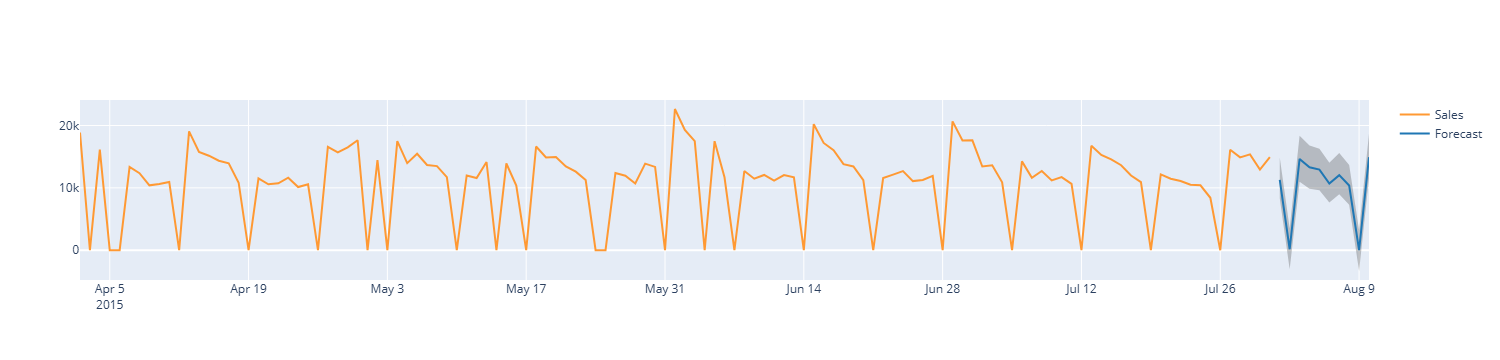

In [18]:
# https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_2_QRC/en-US/hana_ml.visualizers.html
group_key = '84'
from hana_ml.visualizers.visualizer_base import forecast_line_plot
forecast_line_plot(pred_data=predres_hdf.rename_columns({'TIME_STAMP': 'DATE'}).set_index("DATE"),
                   confidence=("LOWER_90%PI", "UPPER_90%PI"),
                   actual_data=data_hdf.select('DATE', 'Sales', 'Store').filter(f""" "Store" = '{group_key}' and DATE > TO_DATE(\'2015-04-01\')""").drop("Store").set_index("DATE"))
# 

## Predict with future rows appended and with TARGET=NULL

In [19]:
data_hdf = conn.table('#RossmannSmall_Train')
tdata_hdf = conn.table('#RossmannSmall_Test')
data_hdf=data_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
print(data_hdf.columns)
#(data_hdf.info())
display(data_hdf.dtypes())
tdata_hdf=tdata_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
print(tdata_hdf.columns)
#display(tdata_hdf.info())

['Store', 'DATE', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


[('Store', 'INT', 10, 10, 10, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0),
 ('Customers', 'INT', 10, 10, 10, 0),
 ('Open', 'INT', 10, 10, 10, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0)]

['Store', 'DATE', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [20]:
predall=data_hdf.set_operations(tdata_hdf.select('*', ('TO_INT(NULL)', 'Customers'), ('TO_INT(NULL)', 'Sales')).to_head('Customers').to_head('Sales').to_head('DATE').to_head('Store'), op='UNION')
predall.filter('"Store" = \'24\'').sort(['DATE']).tail(50).head(5).collect()

,Store,DATE,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,24,2015-07-30,11439.0,884.0,1.0,1,None,1,a,c,4590.0,3.0,2000.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct"
1,24,2015-07-31,14190.0,1082.0,1.0,1,None,1,a,c,4590.0,3.0,2000.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct"
2,24,2015-08-01,NaN,NaN,1.0,0,None,0,a,c,4590.0,3.0,2000.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct"
3,24,2015-08-02,NaN,NaN,0.0,0,None,0,a,c,4590.0,3.0,2000.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct"
4,24,2015-08-03,NaN,NaN,1.0,1,None,1,a,c,4590.0,3.0,2000.0,1,40.0,2011.0,"Jan,Apr,Jul,Oct"


In [21]:
from hana_ml.algorithms.pal.pipeline import Pipeline
#pipe = Pipeline(pipeline={"TSFM": {"args": {}, "inputs": {"data": "ROWDATA"}}})
pipe = Pipeline(pipeline={"TSFM": {"args": {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 30000}, "inputs": {"data": "ROWDATA"}}})
        # No fit(); no explicit skip_fit; nothing to fall back to.
        # {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": [0], "POINT_FORECAST": ["median"], "CLIP_MIN": [0], "CLIP_MAX": [999999]}}
# CONFIDENCE_LEVEL must be one of the specified values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.98]
# , "FORECAST_LENGTH": [10]
# TSFM::predict: no future rows found. Append rows with TARGET=NULL to define the horizon, or pass FORECAST_LENGTH=N
result = pipe.predict(predall.filter('"Store" = \'24\'').deselect('Store'), key='DATE', 
                                             output_prediction_interval=True, confidence_level=0.9)#, endog="HOTELNIGHTS")

In [22]:
import pandas as pd
pd.set_option('max_colwidth', None) 

#display(result.collect())

predres_hdf=result.sort("ID").head(10).select(('TO_DATE("ID")', 'TIME_STAMP'), 
                                          ('JSON_VALUE("SCORES", \'$.value\')', 'Forecast'), 
                                          ('JSON_VALUE("SCORES", \'$.lower\')', 'LOWER_90%PI'), 
                                          ('JSON_VALUE("SCORES", \'$.upper\')', 'UPPER_90%PI'))
predres_hdf.head(5).collect()

,TIME_STAMP,Forecast,LOWER_90%PI,UPPER_90%PI
0,2015-08-01,7959.45751953125,6029.4541015625,10289.6669921875
1,2015-08-02,505.345703125,-1433.37744140625,2856.150390625
2,2015-08-03,13406.369140625,10460.763671875,17483.69921875
3,2015-08-04,11154.6044921875,8777.853515625,14453.375
4,2015-08-05,10480.5380859375,8209.6923828125,13509.7841796875


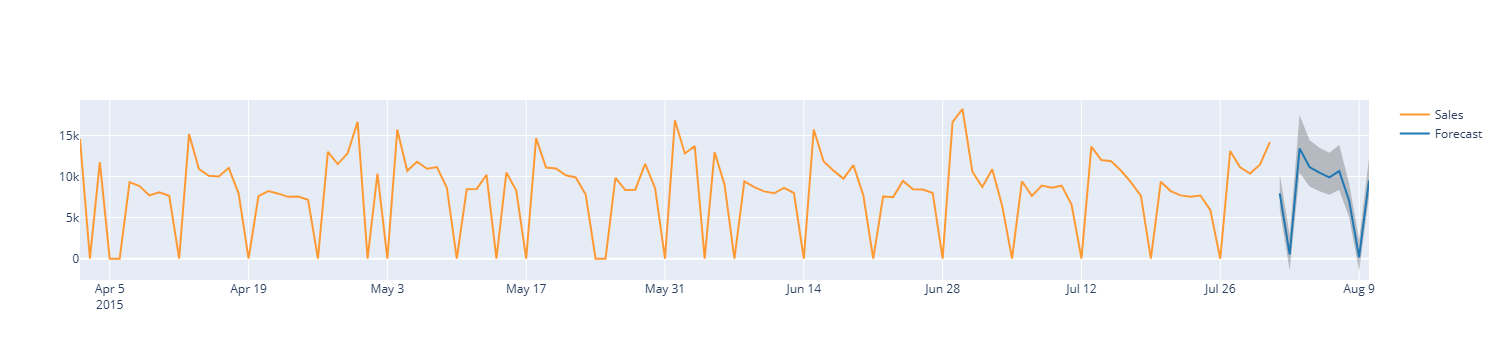

In [23]:
# https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_2_QRC/en-US/hana_ml.visualizers.html
group_key = '24'
from hana_ml.visualizers.visualizer_base import forecast_line_plot
forecast_line_plot(pred_data=predres_hdf.rename_columns({'TIME_STAMP': 'DATE'}).set_index("DATE"),
                   confidence=("LOWER_90%PI", "UPPER_90%PI"),
                   actual_data=data_hdf.select('DATE', 'Sales', 'Store').filter(f""" "Store" = '{group_key}' and DATE > TO_DATE(\'2015-04-01\')""").drop("Store").set_index("DATE"))


# 3.1 RPT-ts Massive Pipeline Predict

In [25]:
#Manual Impute
data_hdf2ref_imputet=conn.sql("""
SELECT "Store", "DATE", "Sales", "Customers", "Open", "Promo", 
              CASE WHEN ("StateHoliday" is NULL) THEN 'NO_HOLIDAY' ELSE "StateHoliday" END AS "StateHoliday",
                "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance",
              CASE WHEN ("CompetitionOpenSinceMonth" is NULL) THEN 0 ELSE "CompetitionOpenSinceMonth" END AS "CompetitionOpenSinceMonth", 
              CASE WHEN ("CompetitionOpenSinceYear" is NULL) THEN 0 ELSE "CompetitionOpenSinceYear" END AS "CompetitionOpenSinceYear", 
               "Promo2", 
              CASE WHEN ("Promo2SinceWeek" is NULL) THEN 0 ELSE "Promo2SinceWeek" END AS "Promo2SinceWeek", 
              CASE WHEN ("Promo2SinceYear" is NULL) THEN 0 ELSE "Promo2SinceYear" END AS "Promo2SinceYear", 
              CASE WHEN ("PromoInterval" is NULL) THEN 'NONE' ELSE "PromoInterval" END AS "PromoInterval", 
                CASE WHEN LOCATE("PromoInterval", 'Jan') > 0 THEN 'YES' ELSE 'NO' END AS PI_JAN, 
 				CASE WHEN LOCATE("PromoInterval", 'Feb') > 0 THEN 'YES' ELSE 'NO' END AS PI_FEB, 
  				CASE WHEN LOCATE("PromoInterval", 'Mar') > 0 THEN 'YES' ELSE 'NO' END AS PI_MAR, 
				CASE WHEN LOCATE("PromoInterval", 'Apr') > 0 THEN 'YES' ELSE 'NO' END AS PI_APR, 
				CASE WHEN LOCATE("PromoInterval", 'May') > 0 THEN 'YES' ELSE 'NO' END AS PI_MAY, 
				CASE WHEN LOCATE("PromoInterval", 'Jun') > 0 THEN 'YES' ELSE 'NO' END AS PI_JUN, 
				CASE WHEN LOCATE("PromoInterval", 'Jul') > 0 THEN 'YES' ELSE 'NO' END AS PI_JUL, 
				CASE WHEN LOCATE("PromoInterval", 'Aug') > 0 THEN 'YES' ELSE 'NO' END AS PI_AUG, 
				CASE WHEN LOCATE("PromoInterval", 'Sept') > 0 THEN 'YES' ELSE 'NO' END AS PI_SEP, 
			    CASE WHEN LOCATE("PromoInterval", 'Oct') > 0 THEN 'YES' ELSE 'NO' END AS PI_OCT, 
			    CASE WHEN LOCATE("PromoInterval", 'Dec') > 0 THEN 'YES' ELSE 'NO' END AS PI_DEC,
				CASE WHEN LOCATE("PromoInterval", 'Nov') > 0 THEN 'YES' ELSE 'NO' END AS PI_NOV
            
				 FROM "ROSSMANN_TRAIN" 
""")
data_hdf2ref_imputet.head(10).collect()    

,Store,DATE,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,PI_MAR,PI_APR,PI_MAY,PI_JUN,PI_JUL,PI_AUG,PI_SEP,PI_OCT,PI_DEC,PI_NOV
0,16,2013-08-11,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
1,16,2013-08-04,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
2,16,2013-07-28,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
3,16,2013-07-21,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
4,16,2013-07-14,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
5,16,2013-07-07,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
6,16,2013-06-30,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
7,16,2013-06-23,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
8,16,2013-06-16,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
9,16,2013-06-09,0,0,0,0,NO_HOLIDAY,0,a,c,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO


In [27]:
tdata_pred_hdf_imputet=conn.sql("""
SELECT "Store", "DATE", TO_INT(NULL) as "Customers", TO_INT("Open") as "Open", "Promo", 
              CASE WHEN ("StateHoliday" is NULL) THEN 'NO_HOLIDAY' ELSE "StateHoliday" END AS "StateHoliday",
                "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance",
              CASE WHEN ("CompetitionOpenSinceMonth" is NULL) THEN 0 ELSE "CompetitionOpenSinceMonth" END AS "CompetitionOpenSinceMonth", 
              CASE WHEN ("CompetitionOpenSinceYear" is NULL) THEN 0 ELSE "CompetitionOpenSinceYear" END AS "CompetitionOpenSinceYear", 
               "Promo2", 
              CASE WHEN ("Promo2SinceWeek" is NULL) THEN 0 ELSE "Promo2SinceWeek" END AS "Promo2SinceWeek", 
              CASE WHEN ("Promo2SinceYear" is NULL) THEN 0 ELSE "Promo2SinceYear" END AS "Promo2SinceYear", 
              CASE WHEN ("PromoInterval" is NULL) THEN 'NONE' ELSE "PromoInterval" END AS "PromoInterval", 
                CASE WHEN LOCATE("PromoInterval", 'Jan') > 0 THEN 'YES' ELSE 'NO' END AS PI_JAN, 
 				CASE WHEN LOCATE("PromoInterval", 'Feb') > 0 THEN 'YES' ELSE 'NO' END AS PI_FEB, 
  				CASE WHEN LOCATE("PromoInterval", 'Mar') > 0 THEN 'YES' ELSE 'NO' END AS PI_MAR, 
				CASE WHEN LOCATE("PromoInterval", 'Apr') > 0 THEN 'YES' ELSE 'NO' END AS PI_APR, 
				CASE WHEN LOCATE("PromoInterval", 'May') > 0 THEN 'YES' ELSE 'NO' END AS PI_MAY, 
				CASE WHEN LOCATE("PromoInterval", 'Jun') > 0 THEN 'YES' ELSE 'NO' END AS PI_JUN, 
				CASE WHEN LOCATE("PromoInterval", 'Jul') > 0 THEN 'YES' ELSE 'NO' END AS PI_JUL, 
				CASE WHEN LOCATE("PromoInterval", 'Aug') > 0 THEN 'YES' ELSE 'NO' END AS PI_AUG, 
				CASE WHEN LOCATE("PromoInterval", 'Sept') > 0 THEN 'YES' ELSE 'NO' END AS PI_SEP, 
			    CASE WHEN LOCATE("PromoInterval", 'Oct') > 0 THEN 'YES' ELSE 'NO' END AS PI_OCT, 
			    CASE WHEN LOCATE("PromoInterval", 'Dec') > 0 THEN 'YES' ELSE 'NO' END AS PI_DEC,
				CASE WHEN LOCATE("PromoInterval", 'Nov') > 0 THEN 'YES' ELSE 'NO' END AS PI_NOV
            
				 FROM (SELECT TO_NVARCHAR("Store", \'00\') AS "Store", "DATE", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"  
                       FROM (SELECT "Store", "DATE", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval" 
                             FROM (SELECT "DATE", "Store", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval" 
                                  FROM (SELECT "Store", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval", "DATE" 
                                        FROM (SELECT "Store", "Date", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval", TO_DATE("Date") AS "DATE" 
                                              FROM (SELECT * FROM "#RossmannSmall_Test") AS "DT_213") AS "DT_219") AS "DT_220") AS "DT_221") AS "DT_222")
""")
tdata_pred_hdf_imputet.head(10).collect() 

,Store,DATE,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,PI_MAR,PI_APR,PI_MAY,PI_JUN,PI_JUL,PI_AUG,PI_SEP,PI_OCT,PI_DEC,PI_NOV
0,131,2015-08-09,None,0,0,NO_HOLIDAY,0,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
1,131,2015-08-08,None,1,0,NO_HOLIDAY,0,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
2,131,2015-08-07,None,1,1,NO_HOLIDAY,1,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
3,131,2015-08-06,None,1,1,NO_HOLIDAY,1,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
4,131,2015-08-05,None,1,1,NO_HOLIDAY,1,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
5,131,2015-08-04,None,1,1,NO_HOLIDAY,1,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
6,131,2015-08-03,None,1,1,NO_HOLIDAY,1,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
7,131,2015-08-02,None,0,0,NO_HOLIDAY,0,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
8,131,2015-08-01,None,1,0,NO_HOLIDAY,0,c,a,920.0,...,NO,NO,NO,NO,NO,NO,NO,NO,NO,NO
9,132,2015-09-17,None,1,1,NO_HOLIDAY,0,d,c,1040.0,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO


In [28]:
predall_imputet=data_hdf2ref_imputet.set_operations(tdata_pred_hdf_imputet.select('*', ('TO_INT(NULL)', 'Sales')).to_head('Customers').to_head('Sales').to_head('DATE').to_head('Store'), op='UNION')
predall_imputet.filter('"Store" = \'24\'').sort(['DATE']).tail(50).head(5).collect()
#data_hdf2ref_imputet
#tdata_pred_hdf_imputet

,Store,DATE,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,PI_MAR,PI_APR,PI_MAY,PI_JUN,PI_JUL,PI_AUG,PI_SEP,PI_OCT,PI_DEC,PI_NOV
0,24,2015-07-30,11439.0,884.0,1,1,NO_HOLIDAY,1,a,c,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO
1,24,2015-07-31,14190.0,1082.0,1,1,NO_HOLIDAY,1,a,c,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO
2,24,2015-08-01,NaN,NaN,1,0,NO_HOLIDAY,0,a,c,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO
3,24,2015-08-02,NaN,NaN,0,0,NO_HOLIDAY,0,a,c,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO
4,24,2015-08-03,NaN,NaN,1,1,NO_HOLIDAY,1,a,c,...,NO,YES,NO,NO,YES,NO,NO,YES,NO,NO


In [29]:
predall_sub=predall.filter('"Store" = \'10\' or "Store" = \'11\'')   # 24, 84 no error
predall_sub.sort(['DATE']).tail(100).head(10).collect()

,Store,DATE,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,11,2015-07-30,7361.0,874.0,1.0,1,None,1,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
1,10,2015-07-30,6186.0,556.0,1.0,1,None,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
2,11,2015-07-31,10457.0,1236.0,1.0,1,None,1,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
3,10,2015-07-31,7185.0,681.0,1.0,1,None,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
4,11,2015-08-01,NaN,NaN,1.0,0,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
5,10,2015-08-01,NaN,NaN,1.0,0,None,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
6,10,2015-08-02,NaN,NaN,0.0,0,None,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
7,11,2015-08-02,NaN,NaN,0.0,0,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
8,10,2015-08-03,NaN,NaN,1.0,1,None,1,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
9,11,2015-08-03,NaN,NaN,1.0,1,None,1,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"


In [30]:
print(predall_imputet.columns)

['Store', 'DATE', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'PI_JAN', 'PI_FEB', 'PI_MAR', 'PI_APR', 'PI_MAY', 'PI_JUN', 'PI_JUL', 'PI_AUG', 'PI_SEP', 'PI_OCT', 'PI_DEC', 'PI_NOV']


In [31]:
from hana_ml.algorithms.pal.massive_pipeline import MassivePipeline
mpipe = MassivePipeline(pipeline={"TSFM": {"args": {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 30000}, "inputs": {"data": "ROWDATA"}}})
#"FORECAST_LENGTH": 48
# Note, endog/target determined by column order: GROUP_ID, DATE_KEY, ENDOG/TARGET, <COVARIATES>
result=mpipe.predict(predall_imputet, group_key='Store', key='DATE', output_prediction_interval=True, confidence_level=0.9)  
        #categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2'], exog=covariates
result.collect()

,Store,ID,SCORES
0,01,2015-08-01,"{""value"":4573.54345703125,""lower"":3789.87158203125,""upper"":5575.0498046875}"
1,01,2015-08-02,"{""value"":122.892578125,""lower"":-501.281005859375,""upper"":888.7412109375}"
2,01,2015-08-03,"{""value"":5084.53466796875,""lower"":4152.4814453125,""upper"":6084.9677734375}"
3,01,2015-08-04,"{""value"":4770.326171875,""lower"":3878.91455078125,""upper"":5741.5078125}"
4,01,2015-08-05,"{""value"":4598.421875,""lower"":3727.423583984375,""upper"":5558.63232421875}"
...,...,...,...
4891,99,2015-09-13,"{""value"":0.0,""lower"":-1086.68017578125,""upper"":1255.610107421875}"
4892,99,2015-09-14,"{""value"":7232.26220703125,""lower"":5626.46240234375,""upper"":9046.75}"
4893,99,2015-09-15,"{""value"":6542.794921875,""lower"":5013.5576171875,""upper"":8216.5478515625}"
4894,99,2015-09-16,"{""value"":6423.119140625,""lower"":4907.39501953125,""upper"":8114.6083984375}"


In [32]:
mpipe.error_.head(100).collect()

,Store,ERROR_TIMESTAMP,ERRORCODE,MESSAGE


In [33]:
#pipe.error_.collect()
#error.collect()


In [34]:
from hana_ml.algorithms.pal.massive_pipeline import MassivePipeline
mpipe3 = MassivePipeline(pipeline={"TSFM": {"args": {"BATCH_SIZE": [128], "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 30000}, "inputs": {"data": "ROWDATA"}}})
#"FORECAST_LENGTH": 48
result=mpipe3.predict(predall_sub, group_key='Store', key='DATE')   
result.collect()

,Store,ID,SCORES
0,10,2015-08-01,5169.427734375
1,10,2015-08-02,361.02880859375
2,10,2015-08-03,7251.31201171875
3,10,2015-08-04,6391.89990234375
4,10,2015-08-05,6017.0771484375
...,...,...,...
91,11,2015-09-13,316.2607421875
92,11,2015-09-14,9079.0625
93,11,2015-09-15,8574.6083984375
94,11,2015-09-16,8480.291015625


In [35]:
mpipe3.error_.head(100).collect()

,Store,ERROR_TIMESTAMP,ERRORCODE,MESSAGE


In [36]:
from hana_ml.algorithms.pal.massive_pipeline import MassivePipeline
mpipe2 = MassivePipeline(pipeline={"TSFM": {"args": {"FORECAST_LENGTH": 48 }, "inputs": {"data": "ROWDATA"}}}) # "BATCH_SIZE": 128, "FORECAST_LENGTH": 12 "OUTPUT_QUANTILE": 0, "POINT_FORECAST": ["median"], "CLIP_MIN": 0, "CLIP_MAX": 999999,
result=mpipe2.predict(predall_sub.select('DATE', 'Sales', 'Store'), group_key='Store', key='DATE', output_prediction_interval=True, confidence_level=0.9 )   #, endog="HOTELNIGHTS" output_prediction_interval=True, confidence_level=0.9
result.collect()

,Store,ID,SCORES
0,10,2015-08-01,"{""value"":5341.1005859375,""lower"":3866.287353515625,""upper"":6858.068359375}"
1,10,2015-08-02,"{""value"":159.146484375,""lower"":-1344.13720703125,""upper"":1828.4609375}"
2,10,2015-08-03,"{""value"":6729.73046875,""lower"":5117.076171875,""upper"":8271.693359375}"
3,10,2015-08-04,"{""value"":6087.85546875,""lower"":4514.16943359375,""upper"":7628.83740234375}"
4,10,2015-08-05,"{""value"":5605.1318359375,""lower"":4090.85205078125,""upper"":7008.67578125}"
...,...,...,...
91,11,2015-09-13,"{""value"":189.96142578125,""lower"":-1694.98193359375,""upper"":2050.7861328125}"
92,11,2015-09-14,"{""value"":8357.986328125,""lower"":6178.001953125,""upper"":10410.091796875}"
93,11,2015-09-15,"{""value"":7730.6259765625,""lower"":5686.2685546875,""upper"":9764.154296875}"
94,11,2015-09-16,"{""value"":7894.619140625,""lower"":5841.3486328125,""upper"":9935.8232421875}"


In [37]:
result.sort('ID').head(5).collect()

,Store,ID,SCORES
0,11,2015-08-01,"{""value"":6625.751953125,""lower"":4715.61328125,""upper"":8897.396484375}"
1,10,2015-08-01,"{""value"":5341.1005859375,""lower"":3866.287353515625,""upper"":6858.068359375}"
2,10,2015-08-02,"{""value"":159.146484375,""lower"":-1344.13720703125,""upper"":1828.4609375}"
3,11,2015-08-02,"{""value"":715.408203125,""lower"":-1296.666015625,""upper"":3009.1376953125}"
4,10,2015-08-03,"{""value"":6729.73046875,""lower"":5117.076171875,""upper"":8271.693359375}"


In [38]:
predres_hdf=result.sort("ID").select('Store', ('TO_DATE("ID")', 'DATE'), 
                                          ('TO_DOUBLE(JSON_VALUE("SCORES", \'$.value\'))', 'Forecast'), 
                                          ('TO_DOUBLE(JSON_VALUE("SCORES", \'$.lower\'))', 'LOWER_90%PI'), 
                                          ('TO_DOUBLE(JSON_VALUE("SCORES", \'$.upper\'))', 'UPPER_90%PI'))
display(predres_hdf.head(3).collect())
display(predres_hdf.dtypes())

,Store,DATE,Forecast,LOWER_90%PI,UPPER_90%PI
0,11,2015-08-01,6625.751953,4715.613281,8897.396484
1,10,2015-08-01,5341.100586,3866.287354,6858.068359
2,10,2015-08-02,159.146484,-1344.137207,1828.460938


[('Store', 'INT', 10, 10, 10, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Forecast', 'DOUBLE', 15, 15, 15, 0),
 ('LOWER_90%PI', 'DOUBLE', 15, 15, 15, 0),
 ('UPPER_90%PI', 'DOUBLE', 15, 15, 15, 0)]

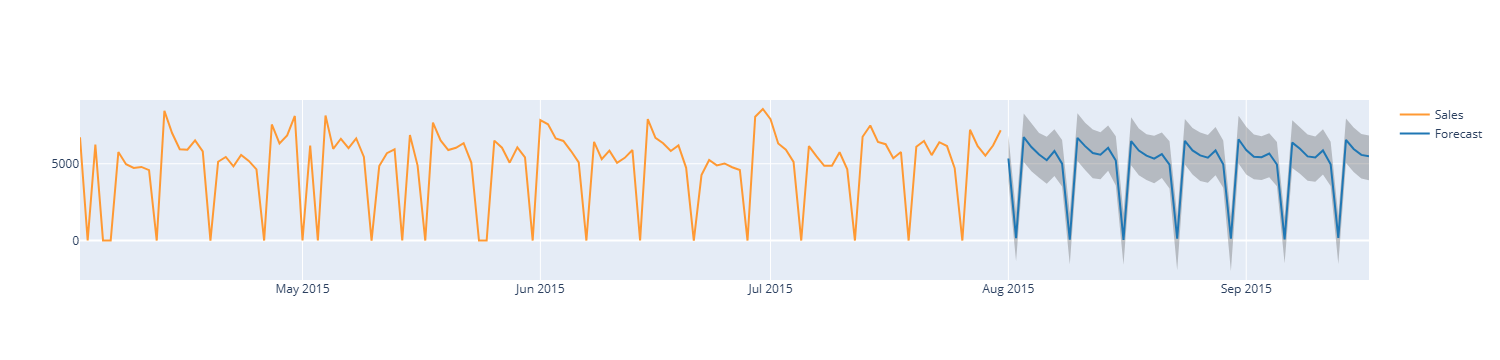

In [39]:
group_key = '10'
from hana_ml.visualizers.visualizer_base import forecast_line_plot
forecast_line_plot(pred_data=predres_hdf.filter(f""" "Store" = '{group_key}'""").drop("Store").set_index("DATE"),
                   confidence=("LOWER_90%PI", "UPPER_90%PI"),
                   actual_data=predall_sub.select('DATE', 'Sales', 'Store').filter(f""" "Store" = '{group_key}' and DATE > TO_DATE(\'2015-04-01\') """).drop("Store").set_index("DATE"))

# Utilize RPT-ts in AutoML TimeSeries (standard and massive)

In [40]:
data_hdf = conn.table('#RossmannSmall_Train')
tdata_hdf = conn.table('#RossmannSmall_Test')
data_hdf=data_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
tdata_hdf=tdata_hdf.select('*', ('TO_DATE("Date")', 'DATE')).drop('Date').to_head('DATE').to_head('Store')
display(data_hdf.dtypes())

[('Store', 'INT', 10, 10, 10, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0),
 ('Customers', 'INT', 10, 10, 10, 0),
 ('Open', 'INT', 10, 10, 10, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0)]

In [41]:
data_hdf_sub=data_hdf.filter('"Store" = \'10\' or "Store" = \'11\'')   # 24, 84 no error
tdata_hdf_sub=tdata_hdf.filter('"Store" = \'10\' or "Store" = \'11\'')   # 24, 84 no error
data_hdf_sub.sort(['DATE']).tail(100).head(10).collect()

,Store,DATE,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,10,2015-06-12,5385,562,1,0,None,0,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
1,11,2015-06-12,6123,953,1,0,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
2,10,2015-06-13,5892,555,1,0,None,0,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
3,11,2015-06-13,5856,827,1,0,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
4,10,2015-06-14,0,0,0,0,None,0,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
5,11,2015-06-14,0,0,0,0,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
6,10,2015-06-15,7902,721,1,1,None,0,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
7,11,2015-06-15,9241,1209,1,1,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"
8,10,2015-06-16,6681,667,1,1,None,0,a,a,3160.0,9.0,2009.0,0,NaN,NaN,None
9,11,2015-06-16,8810,1169,1,1,None,0,a,c,960.0,11.0,2011.0,1,1.0,2012.0,"Jan,Apr,Jul,Oct"


## AutoML TimeSeries Fit

In [42]:
from hana_ml.algorithms.pal.massive_auto_ml import MassiveAutomaticTimeSeries
import uuid, datetime

In [43]:
progress_id = "AutoML_RPT-TS_{}".format((datetime.datetime.now().strftime("%Y%m%d_%H%M%S"))) #format(uuid.uuid1()) 

auto_ts = MassiveAutomaticTimeSeries( population_size=50, # Start to explore 10 different models
                                      search_method='random', # Use random search for the best models, often faster in time series scenarios
                                      with_hyperband=True, #allows for faster optimization convergence, #min_resource=5, max of 5 and (data size)/10 #max_resource=15, defaults to data size
                                      resampling_method='rocv',  # resampling method for time series ='rocv', 'blocked' [with blocked use percentage, default 0.7]
                                      fold_num=3, # rolling window time series model cross-validation, , default 5  
                                                   # gap_num Number of samples to exclude from the end of each train set before the test set.  
                                      scorings={"MAPE":-1.0}, # Optimization objectives, one or multiple: {'RMSE': -1.0}   {MAE":-1.0, "EVAR":1.0} {'MAPE': -1.0}
                                      #elite_number=10, number of best pipeline in best pipeline output
                                      #max_eval_time_mins=1,
                                      random_seed=20260720,
                                      #config_dict='light'  ##'light',      #'default', 'light', <custom> AutoML scenario configuration (selection of algorithms and paramters) 
                                      progress_indicator_id=progress_id)
auto_ts.disable_workload_class_check()
progress_id

'AutoML_RPT-TS_20260923_150351'

In [44]:
auto_ts.disable_auto_sql_content(disable=False) #Disable auto SQL content logging. Use AFL's default progress logging. No, we want to use loggin with PAL_CONTENT.AUTOML_LOG;
auto_ts.persist_progress_log() #Persist the progress log.
auto_ts.set_progress_log_level('full') # scorings output {'full', 'full_best', 'specified'}
auto_ts.disable_log_cleanup(disable=True) #Needed, to access the log from PAL_CONTENT.AUTOML_LOG;

In [46]:
import json
for operator in json.loads(auto_ts.config_dict).keys():
    auto_ts.delete_config_dict(operator)

#auto_ts.update_config_dict('ImputeTS', param_name='IMPUTATION_TYPE', param_config=[0,1,2,9,10,11])
#auto_ts.update_config_dict('ImputeTS', param_name='CompetitionOpenSinceMonth_IMPUTATION_TYPE', param_config=[2]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='CompetitionOpenSinceYear_IMPUTATION_TYPE', param_config=[2]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='Promo2SinceWeek_IMPUTATION_TYPE', param_config=[2]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='Promo2SinceYear_IMPUTATION_TYPE', param_config=[2]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='StateHoliday_IMPUTATION_TYPE', param_config=[[5, 'NO_HOLIDAY']]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='PromoInterval_IMPUTATION_TYPE', param_config=[[5, 'NONE']]) #ALLZERO
#auto_ts.update_config_dict('ImputeTS', param_name='ALPHA', param_config=[0.2, 0.3])
#auto_ts.update_config_dict('ImputeTS', param_name='EXTRAPOLATION', param_config=[0, 1])
#auto_ts.update_config_dict('ImputeTS', param_name='SMOOTH_WIDTH', param_config=[0, 1, 2])
#auto_ts.update_config_dict('ImputeTS', param_name='AUXILIARY_NORMALITYTEST', param_config=[0,1])

auto_ts.update_config_dict('TSFM', param_name='BATCH_SIZE', param_config=[128])  #default
auto_ts.update_config_dict('TSFM', param_name='OUTPUT_QUANTILE', param_config=[0]) #0 disabled (default), 1 quantile_results
auto_ts.update_config_dict('TSFM', param_name='POINT_FORECAST', param_config=['median']) # median, or mean
auto_ts.update_config_dict('TSFM', param_name='CLIP_MIN', param_config=[0]) #Any forecast value below CLIP_MIN is replaced with CLIP_MIN
auto_ts.update_config_dict('TSFM', param_name='CLIP_MAX', param_config=[999999]) #Any forecast value above CLIP_MAX is replaced with CLIP_MAX

auto_ts.display_config_dict()
#auto_ts.verfiy_config_dict()     #VERIFY_CONFIG

  Used Operators    Category
0           TSFM  TimeSeries

------------------------------------------------------------

TSFM
....

             Param    Config
0       BATCH_SIZE     [128]
1  OUTPUT_QUANTILE       [0]
2   POINT_FORECAST  [median]
3         CLIP_MIN       [0]
4         CLIP_MAX  [999999]
------------------------------------------------------------



In [47]:
#predall_sub.select('Store', 'DATE', 'Sales').head(3).collect()
#display(predall_sub.select('Store', 'DATE', 'Sales').dtypes())
#predall_sub2=predall_sub.select(('TO_NVARCHAR("Store", \'00\')', 'Store'), 'DATE', 'Sales' )
#display(predall_sub2.dtypes())

display(data_hdf.select('Store', 'DATE', 'Sales').dtypes())
data_hdf_sub=data_hdf.select(('TO_NVARCHAR("Store", \'00\')', 'Store'), 'DATE', 'Sales' )
display(data_hdf_sub.dtypes())

#INT problem fixed in 2.30.26091509

[('Store', 'INT', 10, 10, 10, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0)]

[('Store', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0)]

In [48]:
#predall2=predall.select(('TO_NVARCHAR("Store", \'00\')', 'Store'), 'DATE', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval' )
data_hdf2=data_hdf.select(('TO_NVARCHAR("Store", \'00\')', 'Store'), 'DATE', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval' )
data_hdf2.save('ROSSMANN_TRAIN', force=True)

data_hdf2ref=conn.table('ROSSMANN_TRAIN')

In [49]:
covariates=['Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

In [50]:
from hana_ml.algorithms.pal.utility import Settings   # make sure to set back to warning
Settings.set_log_level('warning')  # levels: 'info'|'warning'

In [51]:
categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2']

In [52]:
#auto_ts.fit(data=data_hdf2.select('Store', 'DATE', 'Sales'), group_key='Store', key='DATE', endog='Sales')#, exog=covariates)
auto_ts.fit(data=data_hdf2ref_imputet.filter('"Store" = \'10\' '), group_key='Store', key='DATE', endog='Sales',
            categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2'], exog=covariates) #or "Store" = \'11\'
#pipelines = auto_ts.get_best_pipelines()
#display(pipelines)

auto_ts.runtime 
#102 time series, without covariates 120, 141, secs and 0 errors
#102 time series, with covariates 40secs and ALL fail errors (imputation of covariates)
#225 secs with fold_num=10

5.154049873352051

### Check AutoML Fit Errors

In [53]:
auto_ts.error_.head(10).collect().style.set_properties(**{'text-align': 'left'})
#Promo2SinceWeek_IMPUTATION_TYPE=2 #all zero
#PromoInterval_IMPUTATION_TYPE 0: NONE oder 5 SPECIFIED_CATEGORICAL_VALUE
#CATEGORICAL_VARIABLE INT Open, Promo, SchoolHoliday
# #Input data contains null values, please add ImputeTS in the config dict.

,Store,ERROR_TIMESTAMP,ERRORCODE,MESSAGE


In [54]:
print(conn.last_execute_statement)

DO
BEGIN
DECLARE group_id VARCHAR(5000) ARRAY;
DECLARE param_name VARCHAR(5000) ARRAY;
DECLARE int_value INTEGER ARRAY;
DECLARE double_value DOUBLE ARRAY;
DECLARE string_value VARCHAR(5000) ARRAY;
group_id[1] := N'10';
param_name[1] := N'EXECUTION_ID';
int_value[1] := NULL;
double_value[1] := NULL;
string_value[1] := N'10_AutoML_RPT-TS_20260923_150351';
group_id[2] := N'PAL_MASSIVE_PROCESSING_SPECIAL_GROUP_ID2';
param_name[2] := N'CATEGORICAL_VARIABLE';
int_value[2] := NULL;
double_value[2] := NULL;
string_value[2] := N'Open';
group_id[3] := N'PAL_MASSIVE_PROCESSING_SPECIAL_GROUP_ID2';
param_name[3] := N'CATEGORICAL_VARIABLE';
int_value[3] := NULL;
double_value[3] := NULL;
string_value[3] := N'Promo';
group_id[4] := N'PAL_MASSIVE_PROCESSING_SPECIAL_GROUP_ID2';
param_name[4] := N'CATEGORICAL_VARIABLE';
int_value[4] := NULL;
double_value[4] := NULL;
string_value[4] := N'SchoolHoliday';
group_id[5] := N'PAL_MASSIVE_PROCESSING_SPECIAL_GROUP_ID2';
param_name[5] := N'CATEGORICAL_VARIABLE';
i

### Inspect the best pipelines 

In [55]:
# Inspect the elite pipelines from the best result dataframe
auto_ts.best_pipeline_.head(5).collect().style.set_properties(**{'text-align': 'left'})

,Store,ID,PIPELINE,SCORES
0,10,0,"{""TSFM"":{""args"":{""BATCH_SIZE"":128,""OUTPUT_QUANTILE"":0,""POINT_FORECAST"":""median"",""CLIP_MIN"":0,""CLIP_MAX"":999999},""inputs"":{""data"":""ROWDATA""}}}","{""EVAR"":0.9681769826659679,""LAYERS"":1.0,""MAE"":320.7234568927305,""MAPE"":0.09856535917534537,""MAX_ERROR"":1578.1775716145833,""MSE"":197915.8795888532,""R2"":0.9633512454253608,""RMSE"":444.8449999318021,""SPEC"":23965.337944820756,""TIME"":0.09099999999999999,""WMAPE"":0.06786274794621454}"


In [56]:
auto_ts.best_pipeline_.sort('Store').head(10).select('Store', 'ID', ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.MAPE\'), 10, 4)',  'MAPE'), 
                                                                    ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.EVAR\'), 10, 4)',  'EVAR'),
                                                                    ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.MAE\'), 10, 4)',  'MAE'),
                                                                    ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.MAX_ERROR\'), 10, 4)',  'MAX_ERROR'),
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.MSE\'), 10, 4)',  'MSE'),
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.RMSE\'), 10, 4)',  'RMSE'), 
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.R2\'), 10, 4)',  'R2'),
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.WMAPE\'), 10, 4)',  'WMAPE'),
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.SPEC\'), 10, 4)',  'SPEC'),
                                                       ('JSON_VALUE("SCORES", \'$.LAYERS\')',  'LAYERS'), 
                                                     ('TO_DECIMAL(JSON_VALUE("SCORES", \'$.TIME\'), 10, 4)',  'TIME'), 
                                          'PIPELINE').sort(["ID"], desc=False).collect().style.set_properties(**{'text-align': 'left'})
 

,Store,ID,MAPE,EVAR,MAE,MAX_ERROR,MSE,RMSE,R2,WMAPE,SPEC,LAYERS,TIME,PIPELINE
0,10,0,0.0985,0.9681,320.7234,1578.1775,197915.8795,444.8449,0.9633,0.0678,23965.3379,1.0,0.0909,"{""TSFM"":{""args"":{""BATCH_SIZE"":128,""OUTPUT_QUANTILE"":0,""POINT_FORECAST"":""median"",""CLIP_MIN"":0,""CLIP_MAX"":999999},""inputs"":{""data"":""ROWDATA""}}}"


In [57]:
# Explore hyperparms selected from pipeline in model
forecast_pipeline_model_hdf = auto_ts.model_[0]
forecast_pipeline_model_hdf.collect()

Store  ROW_INDEX  \
0     10          0   
1     10          1   
2     10          2   
3     10          3   
4     10          4   
5     10          5   
6     10          6   
7     10          7   
8     10          8   
9     10          9   
10    10         10   
11    10         11   
12    10         12   
13    10         13   
14    10         14   
15    10         15   
16    10         16   
17    10         17   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

### Review AutoML Fit tracked experiments from AutoML-Log

In [58]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
hdf_AUTOML_LOG = conn.sql("SELECT EXECUTION_ID, SEQ, EVENT_KEY, EVENT_TIMESTAMP, EVENT_MESSAGE FROM PAL_CONTENT.AUTOML_LOG order by EVENT_TIMESTAMP desc")
#display(hdf_AUTOML_LOG.head(20).collect().style.set_properties(**{'text-align': 'left'}))

# For massive, EXEC_ID is <GROUP_KEY>_<progress_id>
#99_RPT-TS_65ee4328-ad2a-11f1-a2ee-f47b09a01846
filter="EXECUTION_ID = '99_{}'".format(progress_id)
hdf_AUTOML_LOG = hdf_AUTOML_LOG.filter(filter)
display(hdf_AUTOML_LOG.head(20).collect().style.set_properties(**{'text-align': 'left'}))
filter


,EXECUTION_ID,SEQ,EVENT_KEY,EVENT_TIMESTAMP,EVENT_MESSAGE


"EXECUTION_ID = '99_AutoML_RPT-TS_20260923_150351'"

### Save fitted models

In [59]:
auto_ts_models=auto_ts.model_[0]
auto_ts_models.collect()
#auto_ts.model_[1].collect()
auto_ts_models.select_statement
auto_ts_models.save('#RPT-TS_MODELS', force=True)

In [60]:
newhdf=conn.table('#RPT-TS_MODELS')

# Some display settings
import pandas as pd
pd.set_option('max_colwidth', None) 
display(newhdf.collect())

Store  ROW_INDEX  \
0     10          0   
1     10          1   
2     10          2   
3     10          3   
4     10          4   
5     10          5   
6     10          6   
7     10          7   
8     10          8   
9     10          9   
10    10         10   
11    10         11   
12    10         12   
13    10         13   
14    10         14   
15    10         15   
16    10         16   
17    10         17   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

## Predict with RPT-TS, using pipeline determined from AutoML-Fit

Apply the trained time-series model to create forecasts for these dates
<BR>https://help.sap.com/doc/cd94b08fe2e041c2ba778374572ddba9/2026_2_QRC/en-US/pal/algorithms/hana_ml.algorithms.pal.massive_auto_ml.MassiveAutomaticTimeSeries.html#hana_ml.algorithms.pal.massive_auto_ml.MassiveAutomaticTimeSeries

In [61]:
# Forecast the Shampoo Product Sales for different products
auto_tsP = MassiveAutomaticTimeSeries()
auto_tsP.model_=auto_ts.model_[0]

In [62]:
#topredict_hdf=conn.table('MASSIVE_TS_PREDDATA')
tdata_pred_hdf=tdata_hdf.select(('TO_NVARCHAR("Store", \'00\')', 'Store'), 'DATE') #, ('NULL', 'Sales')
tdata_pred_hdf.head(2).collect()

,Store,DATE
0,131,2015-08-09
1,131,2015-08-08


In [63]:
tdata_pred_hdf.select_statement

'SELECT TO_NVARCHAR("Store", \'00\') AS "Store", "DATE" FROM (SELECT "Store", "DATE", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval" FROM (SELECT "DATE", "Store", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval" FROM (SELECT "Store", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval", "DATE" FROM (SELECT "Store", "Date", "Open", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment", "CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear", "Pro

In [64]:
pred_hdf = auto_tsP.predict(data=tdata_pred_hdf_imputet.filter('"Store" = \'10\' '), group_key='Store', key='DATE', 
                             exog=covariates,   #not supported categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2'],
                            output_prediction_interval=True, confidence_level=0.9)

In [65]:
auto_tsP.error_.head(10).collect().style.set_properties(**{'text-align': 'left'})

,Store,ERROR_TIMESTAMP,ERRORCODE,MESSAGE


In [66]:
pred_hdf.head(5).select('Store', 'ID', 
                        ('JSON_VALUE("SCORES", \'$.value\')', 'Forecast'),                                  
                        ('JSON_VALUE("SCORES", \'$.lower\')', 'LOWER_95%PI'), 
                        ('JSON_VALUE("SCORES", \'$.upper\')', 'UPPER_95%PI')).collect()

,Store,ID,Forecast,LOWER_95%PI,UPPER_95%PI
0,10,2015-08-01,5091.39111328125,4105.6591796875,6263.31787109375
1,10,2015-08-02,193.8037109375,-791.25341796875,1308.45849609375
2,10,2015-08-03,7366.623046875,6069.0078125,8769.701171875
3,10,2015-08-04,6459.0615234375,5340.92724609375,7741.095703125
4,10,2015-08-05,6061.8330078125,4983.3837890625,7250.35400390625


In [67]:
# Some display settings
import pandas as pd
pd.set_option('max_colwidth', None) 

In [68]:
pred_hdfplot=pred_hdf.select('Store', 'ID', 
                        ('JSON_VALUE("SCORES", \'$.value\')', 'Forecast'),                                  
                        ('JSON_VALUE("SCORES", \'$.lower\')', 'LOWER_95%PI'), 
                        ('JSON_VALUE("SCORES", \'$.upper\')', 'UPPER_95%PI'))

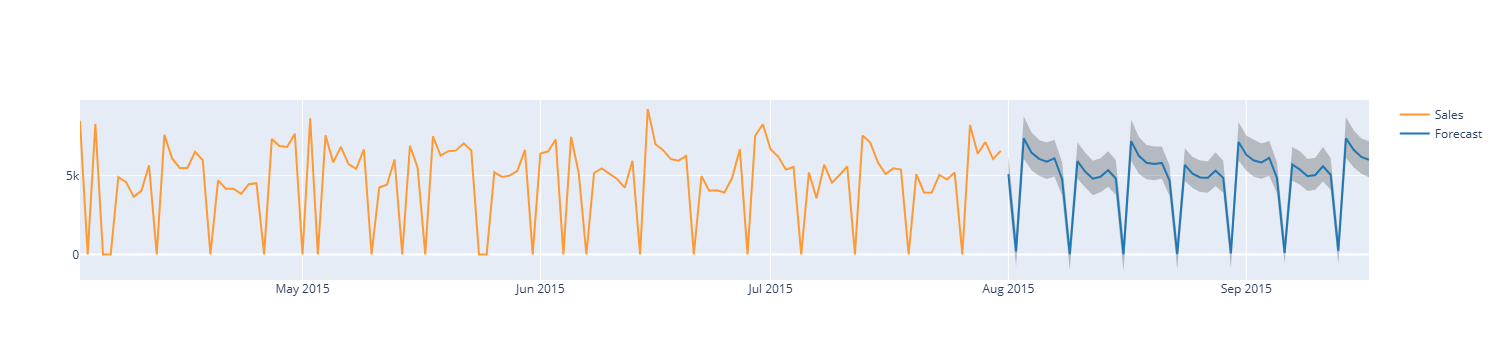

In [70]:
from hana_ml.visualizers.visualizer_base import forecast_line_plot
forecast_line_plot(pred_data=pred_hdfplot.filter('"Store" = \'10\'').drop('Store'), confidence=('LOWER_95%PI', 'UPPER_95%PI'),
                   actual_data=data_hdf.select('Store', 'DATE', 'Sales').filter('"Store" = \'99\' and DATE > TO_DATE(\'2015-04-01\')').drop('Store'))
                   

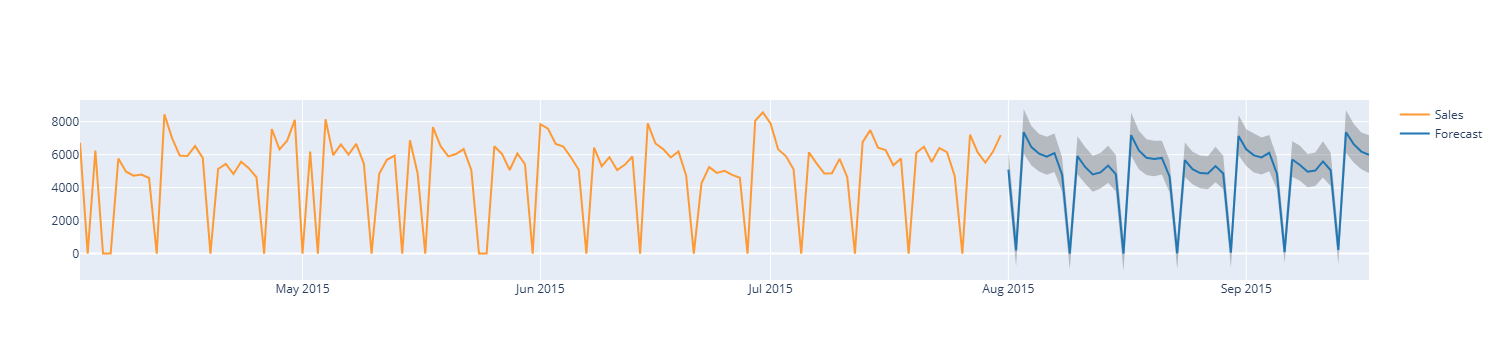

In [71]:
from hana_ml.visualizers.visualizer_base import forecast_line_plot
forecast_line_plot(pred_data=pred_hdfplot.filter('"Store" = \'10\'').drop('Store'), confidence=('LOWER_95%PI', 'UPPER_95%PI'),
                   actual_data=data_hdf.select('Store', 'DATE', 'Sales').filter('"Store" = \'10\' and DATE > TO_DATE(\'2015-04-01\')').drop('Store'))

## Explicit back-testing of the RPT-TS forecast

In [72]:
# Use 2 month of data for backtesting
#data_hdf.select('Store', 'DATE', 'Sales').sort('DATE').tail(1).collect()
bt_hdf=data_hdf.select('Store', 'DATE', 'Sales').filter('DATE > TO_DATE(\'2015-05-31\') and "Store" = \'10\'')

In [73]:
hdf_score_pred, hdf_score_stats=auto_ts.score(data=bt_hdf, 
                                              group_key='Store', key='DATE', endog='Sales')  #, exog=[''])  
display(hdf_score_pred.select('Store', ('ID', 'DATE'), ('SCORE', 'Predicted Sales')).head(5).collect())
display(hdf_score_stats.collect())

,Store,DATE,Predicted Sales
0,10,2015-08-01,4965.650390625
1,10,2015-08-02,9.3564453125
2,10,2015-08-03,6415.06201171875
3,10,2015-08-04,5844.9091796875
4,10,2015-08-05,5467.142578125


,Store,STAT_NAME,STAT_VALUE
0,10,EVAR,-1.2827535291420182
1,10,MAE,2353.26538486168
2,10,MAPE,0.38392061775244446
3,10,MAX_ERROR,8463.62109375
4,10,MSE,11584561.55780968
5,10,R2,-1.3125986663283293
6,10,RMSE,3403.610077228248
7,10,SPEC,14986.685370773566
8,10,WMAPE,0.44973100099490426


In [74]:
# Use 2 month of data for backtesting with covariates
#data_hdf.select('Store', 'DATE', 'Sales').sort('DATE').tail(1).collect()
bt_hdf=data_hdf2ref_imputet.filter('"Store" = \'10\' and DATE > TO_DATE(\'2015-05-31\')')

In [76]:
hdf_score_pred, hdf_score_stats=auto_ts.score(data=bt_hdf, 
                                              group_key='Store', key='DATE', endog='Sales', 
                                              exog=covariates)
display(hdf_score_pred.select('Store', ('ID', 'DATE'), ('SCORE', 'Predicted Sales')).head(5).collect())
display(hdf_score_stats.collect())

,Store,DATE,Predicted Sales
0,10,2015-08-01,7428.28076171875
1,10,2015-08-02,6019.154296875
2,10,2015-08-03,6721.65576171875
3,10,2015-08-04,6644.92724609375
4,10,2015-08-05,6489.28173828125


,Store,STAT_NAME,STAT_VALUE
0,10,EVAR,0.8372374932123767
1,10,MAE,691.5865618596312
2,10,MAPE,0.21203317562958032
3,10,MAX_ERROR,2273.38671875
4,10,MSE,825497.4952168309
5,10,R2,0.8352078844789042
6,10,RMSE,908.5689270588285
7,10,SPEC,1074.6300749231557
8,10,WMAPE,0.13216865328516178


# AutoArima

In [77]:
from hana_ml.algorithms.pal.tsa.auto_arima import AutoARIMA

In [78]:
autoarima = AutoARIMA(search_strategy='stepwise', allow_linear=True, thread_ratio=1.0)

In [87]:
bt_hdf=data_hdf2ref_imputet.filter('"Store" = \'10\' and DATE > TO_DATE(\'2015-05-31\')')
#display(bt_hdf.dtypes())
train_hdf=data_hdf2ref_imputet.filter('"Store" = \'10\' ')
display(train_hdf.dtypes())

[('Store', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('DATE', 'DATE', 10, 10, 10, 0),
 ('Sales', 'INT', 10, 10, 10, 0),
 ('Customers', 'INT', 10, 10, 10, 0),
 ('Open', 'INT', 10, 10, 10, 0),
 ('Promo', 'INT', 10, 10, 10, 0),
 ('StateHoliday', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('SchoolHoliday', 'INT', 10, 10, 10, 0),
 ('StoreType', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('Assortment', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('CompetitionDistance', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceMonth', 'DOUBLE', 15, 15, 15, 0),
 ('CompetitionOpenSinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2', 'INT', 10, 10, 10, 0),
 ('Promo2SinceWeek', 'DOUBLE', 15, 15, 15, 0),
 ('Promo2SinceYear', 'DOUBLE', 15, 15, 15, 0),
 ('PromoInterval', 'NVARCHAR', 5000, 5000, 5000, 0),
 ('PI_JAN', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_FEB', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_MAR', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_APR', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_MAY', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_JUN', 'NVARCHAR', 3, 3, 3, 0),
 ('PI_JUL', 'NVARCHAR

In [88]:
import time
t1 = time.time()
autoarima.fit(data=train_hdf.deselect('Store'), key='DATE', endog='Sales', exog=covariates, categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2'])
print(f'Elapsed time for AutoARIMA is {time.time() - t1} seconds.')
#11.3 secs

Elapsed time for AutoARIMA is 11.312540054321289 seconds.


In [102]:
t2 = time.time()
res_autoarima = autoarima.predict(data = bt_hdf.deselect(['Store', 'Sales']), key='DATE')#, exog=covariates, categorical_variable=['Open', 'Promo', 'SchoolHoliday', 'Promo2'])
print(f'Elapsed time for AutoARIMA is {time.time() - t2} seconds.')
#0.69 secs

Elapsed time for AutoARIMA is 0.5403711795806885 seconds.


In [103]:
res_autoarima.dtypes()

[('DATE(INT)', 'INT', 10, 10, 10, 0),
 ('FORECAST', 'DOUBLE', 15, 15, 15, 0),
 ('SE', 'DOUBLE', 15, 15, 15, 0),
 ('LO80', 'DOUBLE', 15, 15, 15, 0),
 ('HI80', 'DOUBLE', 15, 15, 15, 0),
 ('LO95', 'DOUBLE', 15, 15, 15, 0),
 ('HI95', 'DOUBLE', 15, 15, 15, 0)]

In [106]:
print(bt_hdf.deselect(['Store', 'Sales']).columns)
print(bt_hdf.deselect(['Store', 'Sales']).collect())

['DATE', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'PI_JAN', 'PI_FEB', 'PI_MAR', 'PI_APR', 'PI_MAY', 'PI_JUN', 'PI_JUL', 'PI_AUG', 'PI_SEP', 'PI_OCT', 'PI_DEC', 'PI_NOV']
          DATE  Customers  Open  Promo StateHoliday  SchoolHoliday StoreType  \
0   2015-07-19          0     0      0   NO_HOLIDAY              0         a   
1   2015-07-12          0     0      0   NO_HOLIDAY              0         a   
2   2015-07-05          0     0      0   NO_HOLIDAY              0         a   
3   2015-06-28          0     0      0   NO_HOLIDAY              0         a   
4   2015-06-21          0     0      0   NO_HOLIDAY              0         a   
..         ...        ...   ...    ...          ...            ...       ...   
56  2015-06-03        635     1      1   NO_HOLIDAY              0         a

In [99]:
df_autoarima_pred = res_autoarima.sort_values(by='DATE(INT)', ascending=True)
df_autoarima_pred.collect()

,DATE(INT),FORECAST,SE,LO80,HI80,LO95,HI95
0,0,-1.045661e+12,315.763519,-1.045661e+12,-1.045661e+12,-1.045661e+12,-1.045661e+12
1,1,-1.045661e+12,340.193365,-1.045661e+12,-1.045661e+12,-1.045661e+12,-1.045661e+12
2,2,-1.045661e+12,351.644886,-1.045661e+12,-1.045661e+12,-1.045661e+12,-1.045661e+12
3,3,-1.045661e+12,354.913178,-1.045661e+12,-1.045661e+12,-1.045661e+12,-1.045661e+12
4,4,-1.045661e+12,355.005751,-1.045661e+12,-1.045661e+12,-1.045661e+12,-1.045661e+12
...,...,...,...,...,...,...,...
56,56,-1.059867e+12,377.995378,-1.059867e+12,-1.059867e+12,-1.059867e+12,-1.059867e+12
57,57,-1.059867e+12,378.421292,-1.059867e+12,-1.059867e+12,-1.059867e+12,-1.059867e+12
58,58,-1.059867e+12,378.846728,-1.059867e+12,-1.059867e+12,-1.059867e+12,-1.059867e+12
59,59,-1.059867e+12,379.271686,-1.059867e+12,-1.059867e+12,-1.059867e+12,-1.059867e+12


In [ ]:
bt_hdf.sort('DATE').select(['DATE', 'Sales']).drop('DATE')
df_autoarima_pred.sort('DATE(INT)').select('DATE(INT)', 'FORECAST')

In [109]:
hdf = bt_hdf.sort('DATE').select(['DATE', 'Sales']).drop('DATE').add_id().set_index('ID').join(df_autoarima_pred.sort('DATE(INT)').select('DATE(INT)', 'FORECAST').set_index('DATE(INT)'), how='inner' )
hdf.collect()

,ID,Sales,FORECAST
0,1,7846,-1.045661e+12
1,2,7572,-1.045661e+12
2,3,6648,-1.045661e+12
3,4,6486,-1.045661e+12
4,5,5828,-1.210089e+12
5,6,5087,-1.294743e+12
6,7,0,-1.210089e+12
7,8,6428,-1.210089e+12
8,9,5299,-1.210089e+12
9,10,5853,-1.210089e+12


In [111]:
from hana_ml.algorithms.pal.tsa.accuracy_measure import accuracy_measure
res = accuracy_measure(data=hdf.drop('ID'),
                           evaluation_metric=['mse', 'rmse', 'mpe', 'et',
                                              'mad', 'mase', 'wmape', 'smape',
                                              'mape'])
res.collect()

,STAT_NAME,STAT_VALUE
0,ET,6.946416e+13
1,MAD,1.157736e+12
2,MAPE,1.740253e+08
3,MASE,5.603664e+08
4,MPE,1.740253e+08
5,MSE,1.349063e+24
6,RMSE,1.161492e+12
7,SMAPE,-2.000000e+00
8,WMAPE,2.226387e+08


# Misc

In [ ]:
#print(conn.last_execute_statement)

In [ ]:
# Prepare a predict dataframe to calculate the forecast horizon for the next n periods, here next 10 months
predict_frame = AutoTS_productsales.make_future_dataframe(periods=14)
display(predict_frame.sort(["BOOKING_DATE"]).head(2).collect()) #["BOOKING_DATE", "TS_ID"]

# Forecast the Shampoo Product Sales for different products using the PREDICT method
predict_result = AutoTS_productsales.predict(predict_frame, key='BOOKING_DATE',
                                             output_prediction_interval=True, confidence_level=0.95)

import pandas as pd
pd.set_option('max_colwidth', None) 
display(predict_result.sort("ID").head(1).collect())
predict_result.sort("ID").head(10).select(('TO_DATE("ID")', 'TIME_STAMP'), 
                                          ('JSON_VALUE("SCORES", \'$.value\')', 'Forecast'), 
                                          ('JSON_VALUE("SCORES", \'$.lower\')', 'LOWER_95%PI'), 
                                          ('JSON_VALUE("SCORES", \'$.upper\')', 'UPPER_95%PI')).collect()


In [ ]:
#INSERT INTO #PARAMETER_TABLE VALUES ('PIPELINE', NULL, NULL, '{"TSFM":{"args":{},"inputs":{"data":"ROWDATA"}}}');
#CALL _SYS_AFL.PAL_PIPELINE_FIT(:trainData, :params, model, stat);
  #CALL _SYS_AFL.PAL_PIPELINE_PREDICT(:predData, :model, :params, result, stat);

In [ ]:
#skipfit predict
# The same forecast can be produced in a single call by passing an empty model table and combining the historical context with the future horizon (target NULL) in one input table:
#INSERT INTO #PARAMETER_TABLE VALUES ('PIPELINE', NULL, NULL, '{"TSFM":{"args":{},"inputs":{"data":"ROWDATA"}}}');
combined = SELECT * FROM TSFM_TRAIN_TABLE
             UNION ALL
             SELECT ID, CAST(NULL AS DOUBLE) AS OT, HUFL, HULL, MUFL, MULL, LUFL, LULL FROM TSFM_PRED_TABLE;
    emptyModel = SELECT * FROM EMPTY_MODEL;
CALL _SYS_AFL.PAL_PIPELINE_PREDICT(:combined, :emptyModel, :params, result, stat);

# Appendix
## Create Predict Data Frame

Create a hana_ml DataFrame that contains the dates/months for which we want to create a forecast.
<BR>Begin by identifying the most recent month from the training history

In [ ]:
str_lastdate = agg_hdf.tail(1, ref_col='MONTH').collect().iloc[0,1]
str_lastdate = str(str_lastdate)[0:10]
print(str_lastdate)

Create a hana_ml DataFrame that contains the 1st day of the 12 following months

In [ ]:
from hana_ml.algorithms.pal.random import binomial
months_to_forecast=12
future_hdf = binomial(conn, n=1, p=1, num_random=months_to_forecast)
future_hdf = future_hdf.select('*', (f'''ADD_MONTHS(TO_DATE ('{str_lastdate}', 'YYYY-MM-DD'), ID+1)''', 'MONTH') )
future_hdf = future_hdf.select('MONTH', ('0', 'TARGET'))
future_hdf.head(20).collect()

Create a hana_ml DataFrame that contains the countries for which forecasts should be produced

In [ ]:
countries_hdf = agg_hdf.select('COUNTRYOFRESIDENCE').distinct()
countries_hdf.collect()

Combine the above two hana_ml Dataframes to create a new DataFrame that contains the future dates/months for each of the country (cartesian product)

In [ ]:
topredict_hdf = future_hdf.add_id().set_index('ID').join(countries_hdf.add_id('ID').set_index('ID'), how='cross' )
topredict_hdf = topredict_hdf.drop('ID')
topredict_hdf.head(10).collect()

In [ ]:
topredict_hdf.dtypes()

In [ ]:
topredict_hdf2=topredict_hdf.select('*', ('TO_TIMESTAMP("MONTH")', 'MONTH2'))
display(topredict_hdf2.head(2).collect())
display(topredict_hdf2.dtypes())

In [ ]:
display(topredict_hdf2.head(2).collect())

In [ ]:
topredict_hdf2 = topredict_hdf2.select('COUNTRYOFRESIDENCE', 'MONTH2')
topredict_hdf2 = topredict_hdf2.sort(['COUNTRYOFRESIDENCE', 'MONTH2'])
topredict_hdf2 = topredict_hdf2.rename_columns({'MONTH2': 'MONTH'})

In [ ]:
topredict_hdf2.save('MASSIVE_TS_PREDDATA')